# Experiment 9: Bootstrapping and Cross-Validation on the Iris Dataset
## Aim
Implement bootstrapping and k-fold cross-validation on the Iris dataset, compare the model performance metrics (accuracy, F1-score) obtained using these resampling methods, and discuss the advantages and disadvantages of each.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

## Load and Preprocess the Iris Dataset

In [2]:
iris=load_iris()
df=pd.DataFrame(iris.data,columns=iris.feature_names)
df['species']=pd.Categorical.from_codes(iris.target,iris.target_names)
print(df.shape)
print(df.isnull().sum().sum(),'missing values')
print(df['species'].value_counts())
df.head()

(150, 5)
0 missing values
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
X=iris.data
y=iris.target

model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))

## Baseline: Single Train/Test Split
First, the same model is evaluated with a plain 80/20 hold-out split using 10 different random seeds. If one split were reliable, all ten scores would be nearly identical — the spread shows why a single split is risky.

In [4]:
holdout_acc=[]
for seed in range(10):
    X_tr,X_te,y_tr,y_te=train_test_split(X,y,test_size=0.2,random_state=seed,stratify=y)
    model.fit(X_tr,y_tr)
    holdout_acc.append(accuracy_score(y_te,model.predict(X_te)))

print('Hold-out accuracy per seed:',np.round(holdout_acc,3))
print('Min: %.3f  Max: %.3f  Mean: %.3f  Std: %.3f'%(min(holdout_acc),max(holdout_acc),np.mean(holdout_acc),np.std(holdout_acc)))

Hold-out accuracy per seed: [0.967 0.967 1.    0.867 0.967 0.967 0.933 1.    0.933 0.967]
Min: 0.867  Max: 1.000  Mean: 0.957  Std: 0.037


## Bootstrapping
For each of 1000 iterations: draw a bootstrap sample (with replacement), train on it, and evaluate on the out-of-bag rows. Accuracy and macro-averaged F1-score are recorded each time.

In [5]:
n_iterations=1000
n=len(X)
rng=np.random.RandomState(42)

boot_acc=[]
boot_f1=[]
oob_fraction=[]

t0=time.time()
for i in range(n_iterations):
    train_idx=rng.choice(n,size=n,replace=True)
    oob_idx=np.setdiff1d(np.arange(n),train_idx)
    if len(oob_idx)==0:
        continue
    model.fit(X[train_idx],y[train_idx])
    pred=model.predict(X[oob_idx])
    boot_acc.append(accuracy_score(y[oob_idx],pred))
    boot_f1.append(f1_score(y[oob_idx],pred,average='macro'))
    oob_fraction.append(len(oob_idx)/n)
boot_time=time.time()-t0

print('Bootstrap iterations     :',len(boot_acc))
print('Avg OOB fraction         : %.3f (theory: ~0.368)'%np.mean(oob_fraction))
print('Accuracy  mean +/- std   : %.4f +/- %.4f'%(np.mean(boot_acc),np.std(boot_acc)))
print('Accuracy  95%% interval   : [%.4f, %.4f]'%tuple(np.percentile(boot_acc,[2.5,97.5])))
print('F1 (macro) mean +/- std  : %.4f +/- %.4f'%(np.mean(boot_f1),np.std(boot_f1)))
print('Time taken               : %.2f s'%boot_time)

Bootstrap iterations     : 1000
Avg OOB fraction         : 0.367 (theory: ~0.368)
Accuracy  mean +/- std   : 0.9568 +/- 0.0241
Accuracy  95% interval   : [0.9091, 1.0000]
F1 (macro) mean +/- std  : 0.9560 +/- 0.0246
Time taken               : 4.80 s


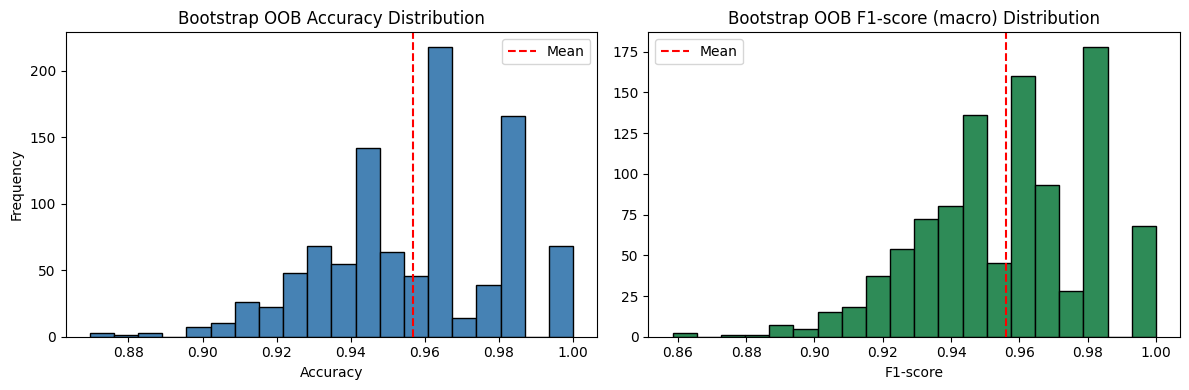

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(boot_acc,bins=20,color='steelblue',edgecolor='k')
axes[0].axvline(np.mean(boot_acc),color='red',linestyle='--',label='Mean')
axes[0].set_title('Bootstrap OOB Accuracy Distribution')
axes[0].set_xlabel('Accuracy')
axes[0].set_ylabel('Frequency')
axes[0].legend()

axes[1].hist(boot_f1,bins=20,color='seagreen',edgecolor='k')
axes[1].axvline(np.mean(boot_f1),color='red',linestyle='--',label='Mean')
axes[1].set_title('Bootstrap OOB F1-score (macro) Distribution')
axes[1].set_xlabel('F1-score')
axes[1].legend()
plt.tight_layout()
plt.show()

## k-Fold Cross-Validation
Stratified 10-fold cross-validation is used as the main setting, with 5-fold shown alongside it.

In [7]:
cv_results={}
for k in [5,10]:
    skf=StratifiedKFold(n_splits=k,shuffle=True,random_state=42)
    t0=time.time()
    res=cross_validate(model,X,y,cv=skf,scoring=['accuracy','f1_macro'])
    cv_results[k]={'acc':res['test_accuracy'],'f1':res['test_f1_macro'],'time':time.time()-t0}
    print(f'{k}-fold CV')
    print('  Accuracy per fold :',np.round(res['test_accuracy'],3))
    print('  Accuracy mean+/-std: %.4f +/- %.4f'%(res['test_accuracy'].mean(),res['test_accuracy'].std()))
    print('  F1 (macro) mean+/-std: %.4f +/- %.4f'%(res['test_f1_macro'].mean(),res['test_f1_macro'].std()))
    print('  Time: %.3f s'%cv_results[k]['time'])
    print()

5-fold CV
  Accuracy per fold : [1.    0.967 0.9   1.    0.9  ]
  Accuracy mean+/-std: 0.9533 +/- 0.0452
  F1 (macro) mean+/-std: 0.9532 +/- 0.0453
  Time: 0.030 s

10-fold CV
  Accuracy per fold : [1.    1.    1.    0.933 0.867 0.933 1.    1.    0.933 0.867]
  Accuracy mean+/-std: 0.9533 +/- 0.0521
  F1 (macro) mean+/-std: 0.9526 +/- 0.0531
  Time: 0.055 s



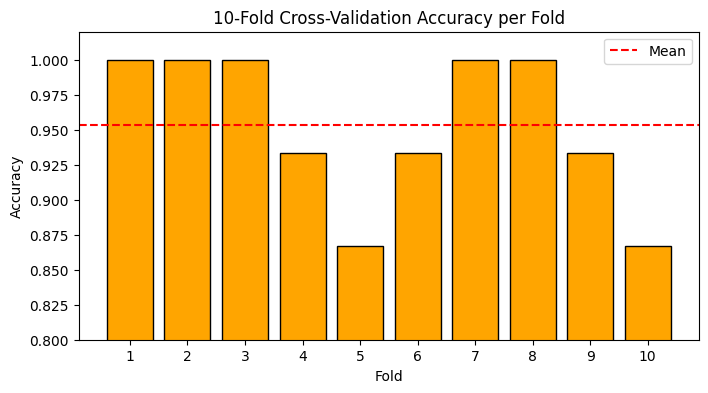

In [8]:
plt.figure(figsize=(8,4))
folds=np.arange(1,11)
plt.bar(folds,cv_results[10]['acc'],color='orange',edgecolor='k')
plt.axhline(cv_results[10]['acc'].mean(),color='red',linestyle='--',label='Mean')
plt.xticks(folds)
plt.ylim(0.8,1.02)
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('10-Fold Cross-Validation Accuracy per Fold')
plt.legend()
plt.show()

### Effect of the Number of Folds (k)
The choice of *k* trades off bias and variance of the estimate, and also computation. Here *k* is varied and the whole 10-fold procedure is repeated 20 times with different shuffles (repeated CV) to see how stable each setting is.

In [9]:
from sklearn.model_selection import RepeatedStratifiedKFold

k_results=[]
for k in [2,3,5,10,15,30]:
    rskf=RepeatedStratifiedKFold(n_splits=k,n_repeats=20,random_state=42)
    t0=time.time()
    res=cross_validate(model,X,y,cv=rskf,scoring='accuracy')
    scores=res['test_score']
    # mean score of each repeat (each repeat = one full k-fold run)
    per_repeat=scores.reshape(20,k).mean(axis=1)
    k_results.append({'k':k,'Mean Accuracy':scores.mean(),
                      'Std across repeats':per_repeat.std(),
                      'Models trained':k*20,'Time (s)':time.time()-t0})

k_df=pd.DataFrame(k_results)
k_df

,k,Mean Accuracy,Std across repeats,Models trained,Time (s)
0,2,0.954667,0.010456,40,0.155994
1,3,0.955000,0.005916,60,0.233002
2,5,0.954333,0.003180,100,0.456460
3,10,0.954333,0.003180,200,0.850116
4,15,0.954000,0.002000,300,1.187778
5,30,0.954667,0.003399,600,2.374937


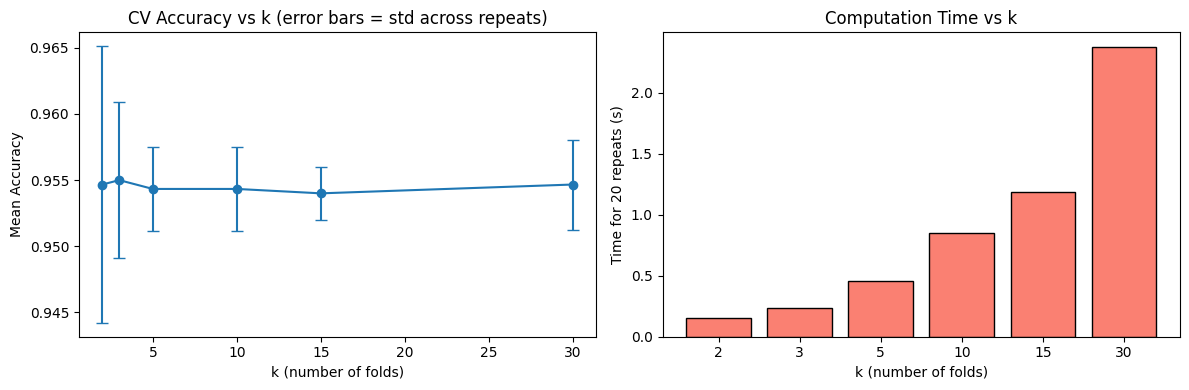

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].errorbar(k_df['k'],k_df['Mean Accuracy'],yerr=k_df['Std across repeats'],marker='o',capsize=4)
axes[0].set_xlabel('k (number of folds)')
axes[0].set_ylabel('Mean Accuracy')
axes[0].set_title('CV Accuracy vs k (error bars = std across repeats)')

axes[1].bar(k_df['k'].astype(str),k_df['Time (s)'],color='salmon',edgecolor='k')
axes[1].set_xlabel('k (number of folds)')
axes[1].set_ylabel('Time for 20 repeats (s)')
axes[1].set_title('Computation Time vs k')
plt.tight_layout()
plt.show()

## Comparison of Bootstrapping and Cross-Validation

In [11]:
summary=pd.DataFrame({
    'Method':['Single hold-out (10 seeds)','Bootstrap (1000, OOB)','5-fold CV','10-fold CV'],
    'Accuracy (mean)':[np.mean(holdout_acc),np.mean(boot_acc),cv_results[5]['acc'].mean(),cv_results[10]['acc'].mean()],
    'F1 macro (mean)':[np.nan,np.mean(boot_f1),cv_results[5]['f1'].mean(),cv_results[10]['f1'].mean()],
    'Accuracy (std)':[np.std(holdout_acc),np.std(boot_acc),cv_results[5]['acc'].std(),cv_results[10]['acc'].std()],
    'Models trained':[10,len(boot_acc),5,10],
    'Time (s)':[np.nan,boot_time,cv_results[5]['time'],cv_results[10]['time']]
})
summary

,Method,Accuracy (mean),F1 macro (mean),Accuracy (std),Models trained,Time (s)
0,Single hold-out (10 seeds),0.956667,NaN,0.036667,10,NaN
1,"Bootstrap (1000, OOB)",0.956775,0.956029,0.024095,1000,4.796157
2,5-fold CV,0.953333,0.953216,0.045216,5,0.029578
3,10-fold CV,0.953333,0.952576,0.052068,10,0.054871


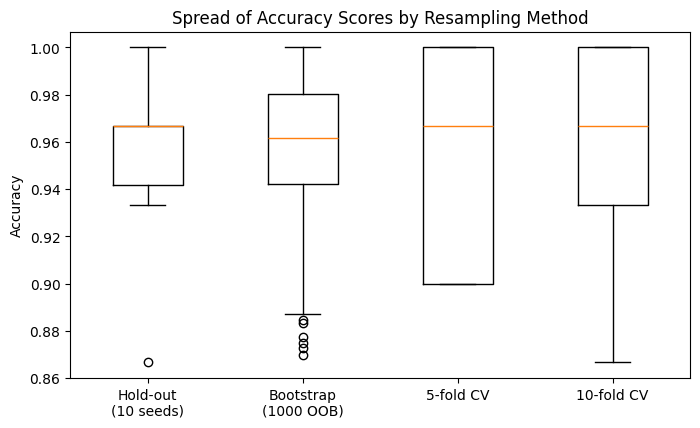

In [12]:
plt.figure(figsize=(8,4.5))
data=[holdout_acc,boot_acc,cv_results[5]['acc'],cv_results[10]['acc']]
plt.boxplot(data,labels=['Hold-out\n(10 seeds)','Bootstrap\n(1000 OOB)','5-fold CV','10-fold CV'])
plt.ylabel('Accuracy')
plt.title('Spread of Accuracy Scores by Resampling Method')
plt.show()